# Regularisation

## Objectives
The objective of this notebook is to fit ridge, lasso and elastic net regressions by hand with numpy, and to see how they compare with least squares on the same features. In the linear regression notebook the model had about 180 coefficients for 1,458 houses, and some of its columns overlap strongly. Regularisation shrinks the coefficients to reduce the variance that this causes, and it copes with collinear columns, so here we keep the columns that were dropped for a high VIF and let the algorithms deal with them. Sections 1 to 6 explain the models and how their hyperparameters are tuned. Sections 7 to 11 build the features, fit and tune the models with 5-fold cross-validation, and submit the lasso.

## 1. The Penalised Model
Least squares chooses the coefficients that fit the training houses as closely as possible. With many coefficients, and columns that overlap, that fit chases noise. The coefficients become large and unstable, and the error on new houses is much worse than on the training houses. Section 3 of the linear regression notebook showed why: the variance of $\hat\beta$ grows as the columns become collinear. Regularisation adds a penalty for large coefficients, so the fit is allowed to be a little worse on the training houses in return for steadier coefficients.

With the target centred and the columns standardised (see below), the penalised loss is
$$L(\beta) = \frac{1}{2n}\sum_{i=1}^{n} (y_i - x_i^\top \beta)^2 + \alpha \left[ \rho \, \|\beta\|_1 + \frac{1 - \rho}{2} \, \|\beta\|_2^2 \right], \qquad \|\beta\|_1 = \sum_j |\beta_j|, \quad \|\beta\|_2^2 = \sum_j \beta_j^2$$
- The first term is the mean squared error that least squares minimises.
- $\alpha \ge 0$ is the strength of the penalty. At $\alpha = 0$ the model is least squares. As $\alpha$ grows, the coefficients are pulled towards 0, and for a large enough $\alpha$ they are all 0, so that every house is predicted at the mean log price. A good $\alpha$ is somewhere in between.
- $\rho$ between 0 and 1 mixes the two penalties. $\rho = 0$ is ridge, which penalises the squares of the coefficients. $\rho = 1$ is the lasso, which penalises their absolute values. A value in between is the elastic net.
- $\alpha$ and $\rho$ are hyperparameters, which are chosen by tuning (section 5).
- The intercept is not penalised, because adding a constant to every price should not change the fit. We centre the target, and add its mean back when predicting.
- The penalty compares coefficients with each other, so the columns must be on the same scale. Otherwise a column in square feet would have a tiny coefficient and a 0/1 flag a large one, and they would be penalised very differently. We standardise every column to a mean of 0 and a standard deviation of 1, using the fitting houses only. The coefficients are then per standard deviation of the column, and we convert them back to the original units for reading.

## 2. Ridge
With $\rho = 0$ and the standardised columns $Z$, the loss is
$$L(\beta) = \frac{1}{2n}\|y - Z\beta\|^2 + \frac{\alpha}{2}\|\beta\|^2$$
Setting the gradient to zero, as for least squares in section 1 of the linear regression notebook, gives
$$-\frac{1}{n} Z^\top (y - Z\beta) + \alpha \beta = 0 \;\Rightarrow\; \hat\beta_{\text{ridge}} = \left( \tfrac{1}{n} Z^\top Z + \alpha I \right)^{-1} \tfrac{1}{n} Z^\top y$$
- For $\alpha > 0$ the matrix can always be inverted, even when columns are exactly collinear, because the penalty adds $\alpha$ to every eigenvalue. Full rank is no longer needed.
- Write the SVD of the columns as $Z = U D V^\top$. The ridge fit shrinks the part of $y$ along the $j$-th principal direction by the factor $d_j^2 / (d_j^2 + n\alpha)$. Directions with a lot of variation in the columns are hardly shrunk. Directions with little variation, which are the combinations of collinear columns, are shrunk the most. This is how ridge removes the unstable part of the fit.
- Ridge shrinks all the coefficients but never sets one exactly to 0.
- It is biased, $E[\hat\beta] \ne \beta$, but its variance is smaller (section 3 of the linear regression notebook). Tuning $\alpha$ looks for the best balance.

## 3. Lasso
With $\rho = 1$ the loss is
$$L(\beta) = \frac{1}{2n}\|y - Z\beta\|^2 + \alpha \|\beta\|_1$$
The absolute value has a corner at 0, so the gradient cannot be set to zero, and there is no closed form. It is solved by coordinate descent: update one coefficient at a time with the others held fixed, and repeat sweeps over all the coefficients until nothing changes. With the columns standardised so that $\frac{1}{n} Z_j^\top Z_j = 1$, the best value of one coefficient is
$$\beta_j \leftarrow S(z_j, \alpha), \qquad z_j = \frac{1}{n} Z_j^\top \Big( y - \sum_{k \ne j} Z_k \beta_k \Big), \qquad S(z, \gamma) = \text{sign}(z) \max(|z| - \gamma, 0)$$
- $z_j$ is how strongly column $j$ is related to what the other columns leave unexplained.
- $S$ is soft-thresholding. It shrinks $z_j$ by $\alpha$, and it returns exactly 0 when $|z_j| \le \alpha$.
- So the lasso selects columns. Those with weak evidence get a coefficient of exactly 0, and the model uses a subset of the columns.
- Among a group of correlated columns, the lasso tends to keep one and drop the others, and which one it keeps can change with the data. This is what letting the algorithm deal with collinear columns means here.

## 4. Elastic Net
The elastic net uses the mixed penalty with $0 < \rho < 1$. The coordinate update becomes
$$\beta_j \leftarrow \frac{S(z_j, \alpha\rho)}{1 + \alpha(1 - \rho)}$$
- The numerator soft-thresholds with the lasso part of the penalty, so weak coefficients are still set to 0.
- The denominator shrinks with the ridge part. This makes correlated columns share the weight between them, instead of one column taking all of it.
- $\rho = 0$ gives ridge and $\rho = 1$ gives the lasso, so one algorithm covers all three. We tune $\rho$ as well as $\alpha$.

## 5. Hyperparameters and Tuning
The coefficients $\beta$ are parameters, which the fit learns from the data. A hyperparameter is a setting that we choose before the fit, and that controls how the fit behaves. Here they are $\alpha$ and $\rho$. For given values of $\alpha$ and $\rho$ the fit returns $\beta$, but nothing in the fit says which values of $\alpha$ and $\rho$ are best. Choosing them is called tuning.

We cannot tune on the error of the training houses. That error is always smallest at $\alpha = 0$, because least squares fits the training houses best, so it would always choose no penalty. We need the error on houses the model has not been fitted on, which is what the competition scores. The Kaggle test set has no `SalePrice` column, so we cannot score it ourselves, and checking the leaderboard for every value of $\alpha$ would cost a submission each and slowly tune the model to the test set. Instead we use 5-fold cross-validation:
- The 1,458 train houses are split into 5 groups of about 292.
- For one value of $\alpha$ (and $\rho$), the model is fitted on 4 groups and scored on the fifth. This is done 5 times, so every house is scored once by a model that never saw it, and the errors are combined into one RMSE of the log price.
- This is repeated for a grid of values of $\alpha$, spaced on a log scale because the effect of $\alpha$ is multiplicative: going from 0.001 to 0.01 matters as much as going from 0.1 to 1.
- The value with the lowest cross-validated RMSE is chosen. The model is then refitted on all of the train houses with that value, and used to predict the test houses.

Notes:
- The cleaning, the encoding and the standardisation also learn from the data. They are refitted on the fitting houses of each fold and then applied to its validation houses, so that no validation house influences them. `clean` and `engineer` take the training data as an argument for this.
- The lowest cross-validated error is a little optimistic, because we chose the best of many values on the same folds. The competition score is the final check.
- The folds are fixed by a seed, so every model is compared on the same splits, and the spread between the folds shows how much a difference matters.
- The elastic net has two hyperparameters, so we try a grid of values of $\rho$, and for each of them a grid of values of $\alpha$. The grid for the lasso and the elastic net starts at the smallest $\alpha$ for which every coefficient is 0, $\max_j |z_j| / \rho$ computed with all the coefficients at 0, and goes down on a log scale.

## 6. What Changes in the Assumptions
- Linear independence is no longer required. Ridge can be fitted with collinear columns, and the lasso and the elastic net choose among them.
- Unbiasedness is lost. The coefficients are deliberately shrunk, so $E[\hat\beta] \ne \beta$, even when exogeneity holds.
- The Gauss–Markov theorem no longer applies, because it only covers unbiased estimators. A biased estimator with a smaller variance can have a lower total error, and that is the point.
- The t-tests, the F-test and the standard errors of the linear regression notebook are no longer valid for the coefficients.
- Normality is still not needed for the fit.
- The loss is still squared error, so constant variance and heavy tails matter as they did for least squares, and the large errors on a few houses still count in full.
- Linearity still matters. Shrinkage does not repair a misspecified shape.

## 7. Features
We use the features of `ols_v02` from the linear regression notebook: the cleaned and encoded columns, the log of the four skewed columns, and the square of `OverallQual`. The one change is that we keep the 18 columns that were dropped there for a high VIF. They are the near copies and the `MSSubClass` dummies, and here we let the penalty deal with them. The steps are in `make_features` in `src/pipeline.py`. The list of skewed columns is found once from all of train with the same rule as before.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.model_selection import KFold

from src.data import load_train, load_test
from src.engineering import engineer, find_skewed
from src.features import clean
from src.pipeline import make_features
from src.regularisation import alpha_max, elastic_net, elastic_net_path, fit_standardiser, gram, ridge, standardise
from src.submission import save_submission

train, test = load_train(), load_test()
train_clean = clean(train, train)

# The skewed columns, found once from all of train, and the features of train and test.
skewed = find_skewed(engineer(train_clean, train_clean))
train_clean, test_clean, features, test_features = make_features(train, test, skewed)
print("Skewed columns:", skewed)
print("Shapes:", features.shape, test_features.shape, "| same columns:", list(features.columns) == list(test_features.columns))

# Collinearity: the variance inflation factors, and the smallest eigenvalue of the correlation matrix.
vif = pd.Series(np.diag(np.linalg.inv(np.corrcoef(features, rowvar=False))), index=features.columns).sort_values(ascending=False)
print(f"Columns with a VIF above 10: {(vif > 10).sum()}, above 100: {(vif > 100).sum()}, largest {vif.max():.1f}")
print(f"Smallest eigenvalue of the correlation matrix: {np.linalg.eigvalsh(np.corrcoef(features, rowvar=False))[0]:.4f}")
display(vif.head(8).round(1).rename("VIF").to_frame().T)

Skewed columns: ['LotFrontage', 'LotArea', 'GrLivArea', 'OpenPorchSF']
Shapes: (1458, 178) (1459, 178) | same columns: True


Columns with a VIF above 10: 22, above 100: 0, largest 45.1
Smallest eigenvalue of the correlation matrix: 0.0075


,BldgType_TwnhsE,SaleType_New,SaleCondition_Partial,HouseStyle_2Story,MSSubClass_190,MSSubClass_160,BldgType_2fmCon,MSSubClass_120
VIF,45.1,43.7,43.4,38.4,36.9,35.9,35.8,35.0


##### Findings:
- There are 178 columns for the 1,458 train houses, and the same 178 for the 1,459 test houses. The four skewed columns are `LotFrontage`, `LotArea`, `GrLivArea` and `OpenPorchSF`, as in the linear regression notebook.
- 22 columns have a VIF above 10, none is above 100, and the largest is 45.1, for `BldgType_TwnhsE`. The highest are the overlapping groups seen before: `SaleType_New` with `SaleCondition_Partial`, and the dwelling type columns `BldgType`, `HouseStyle` and `MSSubClass`.
- The smallest eigenvalue of the correlation matrix is 0.0075, so the columns are not exactly collinear, but some combinations of them vary very little.

## 8. Implementation
The fits are in `src/regularisation.py`, written with numpy. Each takes the standardised columns $Z$ and the centred target through two quantities, $G = Z^\top Z / n$ and $c = Z^\top y / n$.
- `ridge` solves $(G + \alpha I)\beta = c$.
- `elastic_net` runs the coordinate descent of sections 3 and 4, and a ratio of 1 is the lasso.
- `elastic_net_path` fits a whole grid of $\alpha$ from the largest to the smallest, starting each fit from the one before it, which makes the small values of $\alpha$ much faster.

We check them once against scikit-learn on all the train houses. scikit-learn's `Lasso` and `ElasticNet` use the same loss as ours, and its `Ridge` uses $n\alpha$ for our $\alpha$, because its loss has no $1/n$. We ask:
- Do the hand-written fits give the same coefficients as scikit-learn?

In [2]:
# Standardise the columns and centre the target, using all of train.
mean, std = fit_standardiser(features)
Z = standardise(features, mean, std)
y = np.log(train_clean["SalePrice"]).to_numpy()
y_mean = y.mean()
G, c = gram(Z, y - y_mean)
n = len(y)

# The hand-written fits against scikit-learn, at one value of alpha.
alpha = 0.01
library = {
    "Ridge": (ridge(G, c, alpha), Ridge(alpha=n * alpha, fit_intercept=False).fit(Z, y - y_mean).coef_),
    "Lasso": (elastic_net(G, c, alpha, 1.0), Lasso(alpha=alpha, fit_intercept=False, tol=1e-12, max_iter=200000).fit(Z, y - y_mean).coef_),
    "Elastic net (rho 0.5)": (elastic_net(G, c, alpha, 0.5), ElasticNet(alpha=alpha, l1_ratio=0.5, fit_intercept=False, tol=1e-12, max_iter=200000).fit(Z, y - y_mean).coef_),
}
display(pd.DataFrame({name: {"Largest difference": np.abs(mine - theirs).max(), "Coefficients that are not 0 (hand-written)": (mine != 0).sum(), "Coefficients that are not 0 (scikit-learn)": (theirs != 0).sum()} for name, (mine, theirs) in library.items()}).T)

,Largest difference,Coefficients that are not 0 (hand-written),Coefficients that are not 0 (scikit-learn)
Ridge,8.018759e-16,178.0,178.0
Lasso,2.025515e-08,39.0,39.0
Elastic net (rho 0.5),4.409095e-08,66.0,66.0


##### Findings:
- The hand-written ridge matches scikit-learn to 8e-16, the lasso to 2e-8 and the elastic net to 4e-8. They keep the same number of coefficients that are not 0: 178, 39 and 66.
- The small differences for the lasso and the elastic net come from the stopping rule of coordinate descent, which stops when no coefficient changes by more than 1e-8.

## 9. Tuning
We tune with the 5-fold cross-validation of section 5, with the cleaning and the encoding refitted on each fold. For each fold and each value of the hyperparameters, we fit on the fitting houses and score the RMSE of the log price on the validation houses. The grids are:
- $\alpha$ from 0.001 to 100 on a log scale, with 60 values, for ridge.
- 50 values of $\alpha$ on a log scale, from the smallest $\alpha$ at which every coefficient is 0 down to $10^{-4}$ of it, for each of $\rho$ = 0.1, 0.3, 0.5, 0.7, 0.9 and 1. A $\rho$ of 1 is the lasso.

Least squares on the same features is the reference, as the case of $\alpha = 0$. We ask:
- Does any penalty beat least squares on unseen houses, and by how much?
- Which values of $\alpha$ and $\rho$ are best, and how flat is the curve around them?
- How much do the folds disagree?

,alpha,CV RMSE,Lowest fold,Highest fold
Least squares,0.0000,0.1186,0.1062,0.1449
Ridge,0.0732,0.1151,0.1044,0.1393
Elastic net 0.1,0.0205,0.1107,0.0990,0.1369
Elastic net 0.3,0.0083,0.1106,0.0985,0.1367
Elastic net 0.5,0.0050,0.1105,0.0985,0.1366
Elastic net 0.7,0.0035,0.1105,0.0985,0.1365
Elastic net 0.9,0.0028,0.1105,0.0985,0.1365
Lasso,0.0025,0.1105,0.0985,0.1365


,Least squares,Ridge,Lasso
Fold 1,0.1210,0.1152,0.1095
Fold 2,0.1078,0.1056,0.0985
Fold 3,0.1449,0.1393,0.1365
Fold 4,0.1085,0.1076,0.1034
Fold 5,0.1062,0.1044,0.1003


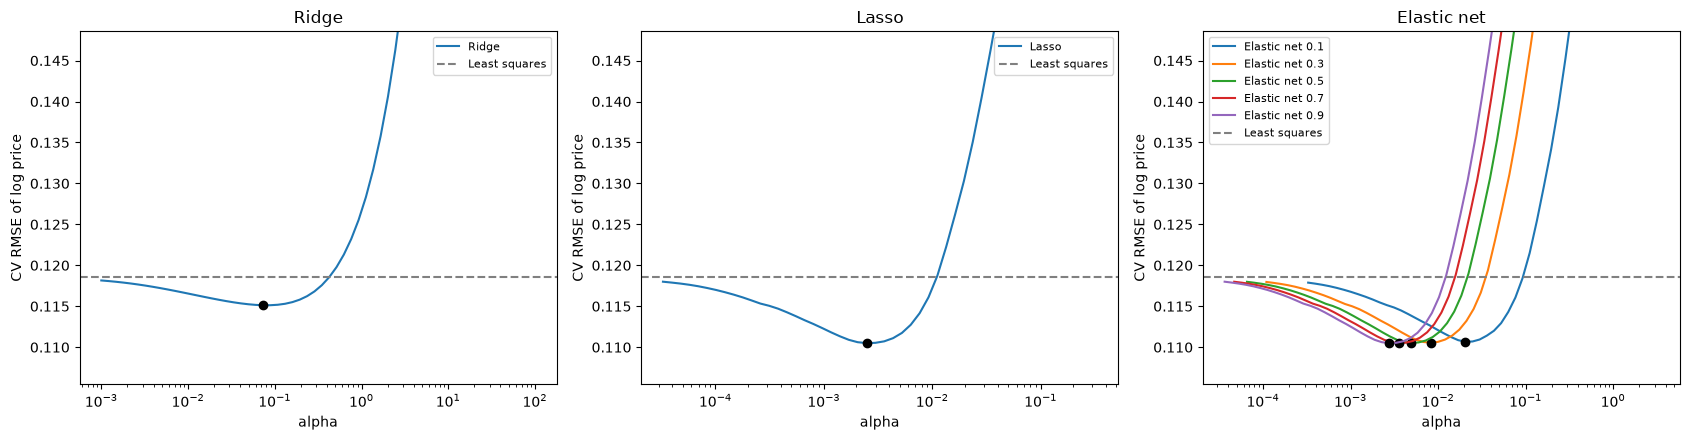

In [3]:
# The grids of alpha: ridge on a log scale, and the lasso and elastic net below the alpha where every coefficient is 0.
RATIOS = [0.1, 0.3, 0.5, 0.7, 0.9, 1.0]
ridge_alphas = np.logspace(-3, 2, 60)
net_alphas = {ratio: alpha_max(c, ratio) * np.logspace(0, -4, 50) for ratio in RATIOS}
names = {ratio: ("Lasso" if ratio == 1.0 else f"Elastic net {ratio}") for ratio in RATIOS}

# Mean squared error on each validation fold, for every model and value of alpha.
folds = KFold(5, shuffle=True, random_state=0)
grid_sizes = {"Least squares": 1, "Ridge": len(ridge_alphas), **{names[ratio]: len(net_alphas[ratio]) for ratio in RATIOS}}
squared = {name: np.zeros((5, size)) for name, size in grid_sizes.items()}
counts = []
for fold, (fit_index, validation_index) in enumerate(folds.split(train)):
    # Refit the cleaning, the encoding and the standardisation on the fold's fitting houses only.
    fit_clean, validation_clean, fit_features, validation_features = make_features(train.iloc[fit_index], train.iloc[validation_index], skewed)
    fit_mean, fit_std = fit_standardiser(fit_features)
    Z_fit, Z_validation = standardise(fit_features, fit_mean, fit_std), standardise(validation_features, fit_mean, fit_std)
    y_fit, y_validation = np.log(fit_clean["SalePrice"]).to_numpy(), np.log(validation_clean["SalePrice"]).to_numpy()
    G_fold, c_fold = gram(Z_fit, y_fit - y_fit.mean())
    counts.append(len(y_validation))

    def validation_mse(betas):
        # One row of coefficients for each value of alpha.
        return ((y_validation[:, None] - (y_fit.mean() + Z_validation @ betas.T)) ** 2).mean(axis=0)

    squared["Least squares"][fold] = validation_mse(np.linalg.lstsq(Z_fit, y_fit - y_fit.mean(), rcond=None)[0][None, :])
    squared["Ridge"][fold] = validation_mse(np.array([ridge(G_fold, c_fold, a) for a in ridge_alphas]))
    for ratio in RATIOS:
        squared[names[ratio]][fold] = validation_mse(elastic_net_path(G_fold, c_fold, net_alphas[ratio], ratio))

# RMSE over all the houses, and the RMSE of each fold.
weights = np.array(counts) / sum(counts)
overall = {name: np.sqrt(weights @ mse) for name, mse in squared.items()}
fold_rmse = {name: np.sqrt(mse) for name, mse in squared.items()}
alphas_of = {"Least squares": np.array([0.0]), "Ridge": ridge_alphas, **{names[ratio]: net_alphas[ratio] for ratio in RATIOS}}

# The best value of alpha for each model.
rows = {}
for name in grid_sizes:
    best = overall[name].argmin()
    rows[name] = {"alpha": alphas_of[name][best], "CV RMSE": overall[name][best], "Lowest fold": fold_rmse[name][:, best].min(), "Highest fold": fold_rmse[name][:, best].max()}
results = pd.DataFrame(rows).T
display(results.round(4))

# The RMSE of each fold at the best value, for the three main models.
display(pd.DataFrame({name: fold_rmse[name][:, overall[name].argmin()] for name in ["Least squares", "Ridge", "Lasso"]}, index=[f"Fold {i}" for i in range(1, 6)]).round(4))

# The curves of cross-validated RMSE against alpha, with least squares as a line.
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
reference = overall["Least squares"][0]
for ax, title, model_names in zip(axes, ["Ridge", "Lasso", "Elastic net"], [["Ridge"], ["Lasso"], [names[r] for r in RATIOS[:-1]]]):
    for name in model_names:
        ax.plot(alphas_of[name], overall[name], label=name)
        ax.plot(alphas_of[name][overall[name].argmin()], overall[name].min(), "ko")
    ax.axhline(reference, color="grey", linestyle="--", label="Least squares")
    ax.set(xscale="log", title=title, xlabel="alpha", ylabel="CV RMSE of log price", ylim=(results["CV RMSE"].min() - 0.005, reference + 0.03))
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

##### Findings:
- Least squares on the 178 columns has a cross-validated RMSE of the log price of 0.1186.
- Ridge is best at an alpha of 0.0732, with 0.1151. The lasso is best at an alpha of 0.0025, with 0.1105, which is 0.0081 lower than least squares.
- Every value of rho from 0.1 to 0.9 reaches 0.1105 to 0.1107, so the elastic net is no better than the lasso. The best is a rho of 0.9 with an alpha of 0.0028, at 0.1105. The ridge part of the penalty adds nothing here.
- The ranking is the same in all five folds: the lasso beats ridge, and ridge beats least squares. The lasso gains 0.0115, 0.0093, 0.0084, 0.0051 and 0.0059 over least squares.
- The folds disagree on the level, from 0.0985 to 0.1365 for the lasso, and fold 3 is the hardest for every model, but they agree on the ranking.
- The curves have a clear minimum and are shallow around it, so an alpha a little either side of the best costs very little. A large alpha quickly makes the error much worse, as the coefficients shrink to 0.

##### Decision:
Use an alpha of 0.0732 for ridge, an alpha of 0.0025 for the lasso, and a rho of 0.9 with an alpha of 0.0028 for the elastic net. The cross-validated error of the best value is slightly optimistic, because we chose the best of many values on the same folds.

## 10. The Fitted Models
We refit each model on all the train houses with its best values of $\alpha$ and $\rho$, and look at what the penalty did to the coefficients. The elastic net uses the best of the values of $\rho$ below 1. We ask:
- How does the error on unseen houses compare with the error on the fitting houses?
- How many coefficients does each model keep?
- What happens to the columns with a high VIF?

Best elastic net: rho 0.9, alpha 0.0028


,Coefficients that are not 0,In-sample RMSE,CV RMSE,Gap
Least squares,178,0.0934,0.1186,0.0251
Ridge,178,0.0955,0.1151,0.0196
Lasso,101,0.0978,0.1105,0.0127
Elastic net,101,0.0978,0.1105,0.0127


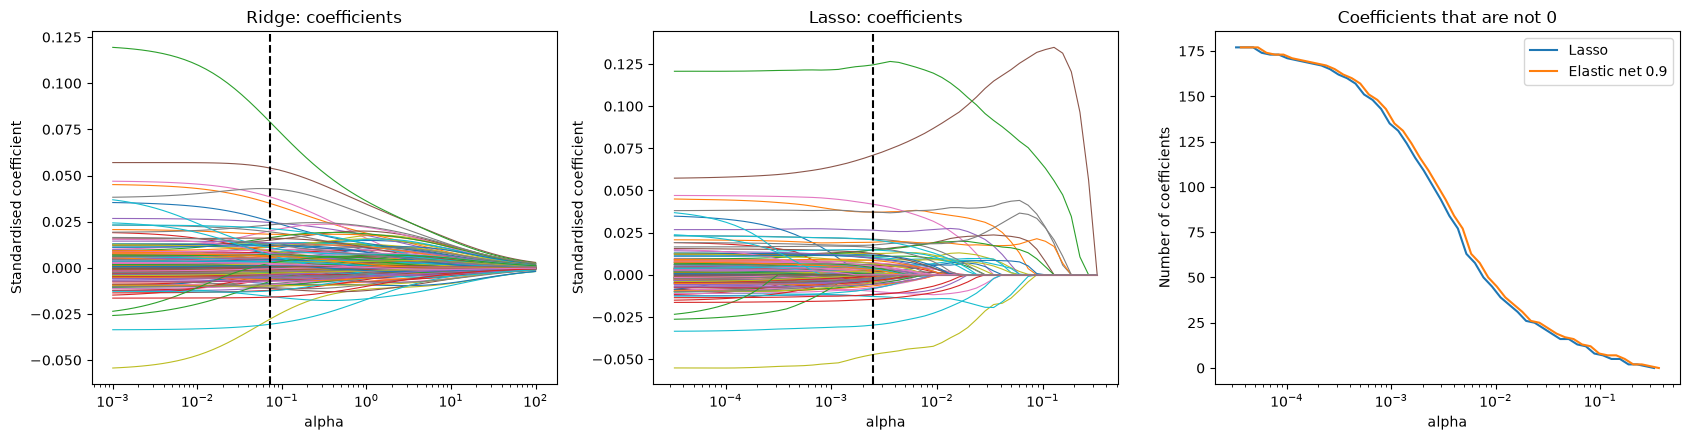

,VIF,Least squares,Ridge,Lasso,Elastic net
BldgType_TwnhsE,45.073,-0.005,-0.002,0.000,0.000
SaleType_New,43.708,0.040,0.011,0.015,0.015
SaleCondition_Partial,43.431,-0.026,0.002,0.000,0.000
HouseStyle_2Story,38.423,-0.027,-0.007,-0.000,-0.000
MSSubClass_190,36.915,-0.011,-0.003,-0.000,-0.000
MSSubClass_160,35.855,-0.005,-0.006,-0.008,-0.008
BldgType_2fmCon,35.814,0.006,-0.001,-0.000,-0.000
MSSubClass_120,34.986,0.004,0.002,0.000,0.000
MSSubClass_60,24.194,-0.003,-0.002,-0.000,-0.000
GarageCond,20.698,0.010,0.004,0.000,0.000


Columns with a VIF above 10 that the lasso sets to 0: 13 of 22


In [4]:
# Refit on all of train at the best values.
best_net = results.drop(index=["Least squares", "Ridge", "Lasso"])["CV RMSE"].idxmin()
best_ratio = {name: ratio for ratio, name in names.items()}[best_net]
betas = {
    "Least squares": np.linalg.lstsq(Z, y - y_mean, rcond=None)[0],
    "Ridge": ridge(G, c, results.loc["Ridge", "alpha"]),
    "Lasso": elastic_net(G, c, results.loc["Lasso", "alpha"], 1.0),
    "Elastic net": elastic_net(G, c, results.loc[best_net, "alpha"], best_ratio),
}
cv_rmse = {"Least squares": results.loc["Least squares", "CV RMSE"], "Ridge": results.loc["Ridge", "CV RMSE"], "Lasso": results.loc["Lasso", "CV RMSE"], "Elastic net": results.loc[best_net, "CV RMSE"]}
summary = pd.DataFrame(
    {
        "Coefficients that are not 0": {name: (beta != 0).sum() for name, beta in betas.items()},
        "In-sample RMSE": {name: np.sqrt(np.mean((y - y_mean - Z @ beta) ** 2)) for name, beta in betas.items()},
        "CV RMSE": cv_rmse,
    }
)
summary["Gap"] = summary["CV RMSE"] - summary["In-sample RMSE"]
print(f"Best elastic net: rho {best_ratio}, alpha {results.loc[best_net, 'alpha']:.4f}")
display(summary.round(4))

# The coefficient paths on all of train: ridge, lasso, and the number of coefficients that are not 0.
ridge_path = np.array([ridge(G, c, a) for a in ridge_alphas])
lasso_path = elastic_net_path(G, c, net_alphas[1.0], 1.0)
net_path = elastic_net_path(G, c, net_alphas[best_ratio], best_ratio)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(ridge_alphas, ridge_path, linewidth=0.8)
axes[0].axvline(results.loc["Ridge", "alpha"], color="black", linestyle="--")
axes[0].set(xscale="log", title="Ridge: coefficients", xlabel="alpha", ylabel="Standardised coefficient")
axes[1].plot(net_alphas[1.0], lasso_path, linewidth=0.8)
axes[1].axvline(results.loc["Lasso", "alpha"], color="black", linestyle="--")
axes[1].set(xscale="log", title="Lasso: coefficients", xlabel="alpha", ylabel="Standardised coefficient")
axes[2].plot(net_alphas[1.0], (lasso_path != 0).sum(axis=1), label="Lasso")
axes[2].plot(net_alphas[best_ratio], (net_path != 0).sum(axis=1), label=best_net)
axes[2].set(xscale="log", title="Coefficients that are not 0", xlabel="alpha", ylabel="Number of coefficients")
axes[2].legend()
plt.tight_layout()
plt.show()

# The columns with the highest VIF: their standardised coefficients in each model.
high = vif.head(10).index
table = pd.DataFrame({name: pd.Series(beta, index=features.columns)[high] for name, beta in betas.items()})
table.insert(0, "VIF", vif[high])
display(table.round(3))
print("Columns with a VIF above 10 that the lasso sets to 0:", int((pd.Series(betas["Lasso"], index=features.columns)[vif[vif > 10].index] == 0).sum()), "of", int((vif > 10).sum()))

##### Findings:
- The penalty trades fit for stability. The in-sample RMSE rises from 0.0934 for least squares to 0.0955 for ridge and 0.0978 for the lasso, while the cross-validated RMSE falls from 0.1186 to 0.1151 and 0.1105. The gap between the two shrinks from 0.0251 to 0.0196 and 0.0127.
- Ridge keeps all 178 coefficients but shrinks them. The lasso keeps 101 and sets 77 to 0. The elastic net with a rho of 0.9 keeps the same 101 and has the same errors.
- The coefficient paths show the difference. The ridge paths shrink smoothly together towards 0, while the lasso paths reach 0 one at a time as alpha grows, and the number of coefficients that are not 0 falls steadily from 178.
- Least squares gives near copies large coefficients with opposite signs. `SaleType_New` is 0.040 and `SaleCondition_Partial` is -0.026, per standard deviation. Ridge shares the weight, with 0.011 and 0.002. The lasso keeps `SaleType_New` at 0.015 and sets `SaleCondition_Partial` to 0.
- Of the 22 columns with a VIF above 10, the lasso sets 13 to 0, so it decides for itself which of the overlapping columns to keep.

##### Decision:
Use the lasso for the submission. The elastic net is the same model for practical purposes, so it is not submitted separately.

## 11. Submission
The lasso predicts the log price of the test houses, using the standardisation of all of train, and the prediction is turned back into a price with the exponential. As in the linear regression notebook, no correction is needed for the score. The lasso is the model we submit. It has the lowest cross-validated error, tied with the elastic net, which is almost the same model, and it has one hyperparameter instead of two. The file is saved as `lasso_v01.csv` by `save_submission`, which checks it against the sample file. We ask:
- Are the predictions sensible, and how do they treat the extrapolated Id 2550?

In [5]:
# Predict the test houses with the lasso, and save the submission.
Z_test = standardise(test_features, mean, std)
prices = np.exp(y_mean + Z_test @ betas["Lasso"])
print("Saved:", save_submission(test_features.index, prices, "lasso", 1))
display(pd.Series({"Lowest": prices.min(), "Median": np.median(prices), "Highest": prices.max(), "Id 2550": prices[test_features.index.get_loc(2550)]}, name="Predicted price").round(0).to_frame().T)

Saved: ../submissions/lasso_v01.csv


,Lowest,Median,Highest,Id 2550
Predicted price,41653.0,157275.0,1034478.0,1034478.0
